# Data Visualizations

In [1]:
# datascience
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')


In [2]:
# polars
import polars as pl
from IPython.display import display
import hvplot.polars


## Review

In [3]:
# datascience
united_flights = Table.read_table('united.csv')
united_flights.show(3)


Date,Flight Number,Destination,Delay
6/1/15,73,HNL,257
6/1/15,217,EWR,28
6/1/15,237,STL,-3


In [4]:
# polars
united_flights_pl = pl.read_csv('united.csv', eol_char='\r')
united_flights_pl.head(3)


Date,Flight Number,Destination,Delay
str,i64,str,i64
"""6/1/15""",73,"""HNL""",257
"""6/1/15""",217,"""EWR""",28
"""6/1/15""",237,"""STL""",-3


**DISCUSS:** On what fraction of days was flight 73 delayed? 

In [5]:
# datascience
#  (# of times that 73 was delayed) / (# of times that 73 existed)
flight73 = united_flights.where('Flight Number', 73)
flight73.where('Delay', are.above(0)).num_rows / flight73.num_rows


0.8260869565217391

In [6]:
# polars
#  (# of times that 73 was delayed) / (# of times that 73 existed)
flight73_pl = united_flights_pl.filter((pl.col('Flight Number') == (73)))
flight73_pl.filter((pl.col('Delay') > (0))).height / flight73_pl.height


0.8260869565217391

**DISCUSS:** Is the Flight Number attribute *numerical* or *categorical*?

## US Census Visualization

In [7]:
# datascience
full = Table.read_table('nc-est2025-agesex-res.csv')
partial = full.where('AGE', are.below(100)).select('SEX', 'AGE', 'POPESTIMATE2025')
us_pop_2025 = partial.relabeled(2, '2025')
us_pop_2025.show(5)


SEX,AGE,2025
0,0,3618898
0,1,3642657
0,2,3725891
0,3,3791993
0,4,3712428


In [8]:
# polars
full_pl = pl.read_csv('nc-est2025-agesex-res.csv')
partial_pl = full_pl.filter((pl.col('AGE') < (100))).select('SEX', 'AGE', 'POPESTIMATE2025')
us_pop_2025_pl = partial_pl.rename({partial_pl.columns[2]: '2025'})
us_pop_2025_pl.head(5)


SEX,AGE,2025
i64,i64,i64
0,0,3618898
0,1,3642657
0,2,3725891
0,3,3791993
0,4,3712428


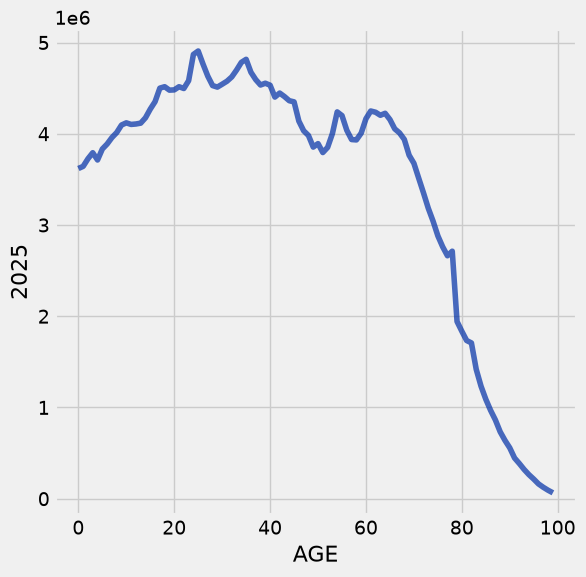

In [9]:
# datascience
us_pop_2025.where('SEX', 0).plot('AGE', '2025')


In [10]:
# polars
# hvplot
us_pop_2025_pl.filter((pl.col('SEX') == (0))).hvplot.line(x='AGE', y='2025')


:Curve   [AGE]   (2025)

**DISCUSS**: What is one thing interesting about this plot?

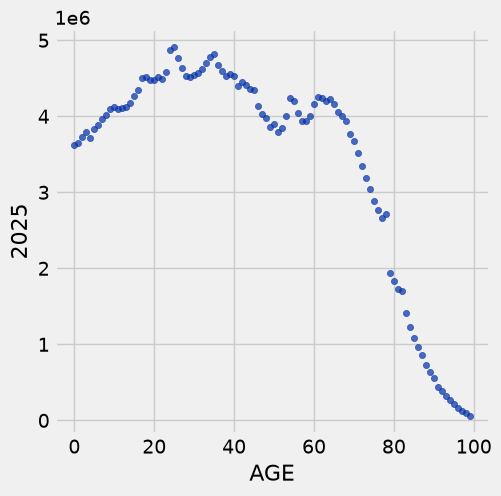

In [11]:
# datascience
us_pop_2025.where('SEX', 0).scatter('AGE', '2025')


In [12]:
# polars
# hvplot
us_pop_2025_pl.filter((pl.col('SEX') == (0))).hvplot.scatter(x='AGE', y='2025')


:Scatter   [AGE]   (2025)

**DISCUSS**: What does the expression below compute?

In [13]:
# datascience
np.average(us_pop_2025.where('SEX', 0).column('AGE'))


49.5

In [14]:
# polars
(us_pop_2025_pl.filter((pl.col('SEX') == (0))).get_column('AGE')).mean()


49.5

Compute the average age of people in the US in 2019:

In [15]:
# datascience
everyone = us_pop_2025.where('SEX', 0)
total_years = sum(everyone.column('AGE') * everyone.column('2025'))
total_people = sum(everyone.column('2025'))
total_years / total_people


40.10912322404058

In [16]:
# polars
everyone_pl = us_pop_2025_pl.filter((pl.col('SEX') == (0)))
total_years_pl = sum(everyone_pl.get_column('AGE') * everyone_pl.get_column('2025'))
total_people_pl = sum(everyone_pl.get_column('2025'))
total_years_pl / total_people_pl


40.10912322404058

### Males vs Females

In [17]:
# datascience
# Let's compare male and female counts per age
males = us_pop_2025.where('SEX', 1).drop('SEX')
females = us_pop_2025.where('SEX', 2).drop('SEX')


In [18]:
# polars
# Let's compare male and female counts per age
males_pl = us_pop_2025_pl.filter((pl.col('SEX') == (1))).drop('SEX')
females_pl = us_pop_2025_pl.filter((pl.col('SEX') == (2))).drop('SEX')


In [19]:
# datascience
pop_2025 = Table().with_columns(
    'Age', males.column('AGE'),
    'Males', males.column('2025'),
    'Females', females.column('2025')
)
pop_2025


Age,Males,Females
0,1851154,1767744
1,1862589,1780068
2,1903014,1822877
3,1935244,1856749
4,1897991,1814437
5,1957818,1875185
6,1982503,1905010
7,2020117,1938268
8,2049622,1963487
9,2091459,2004252


In [20]:
# polars
pop_2025_pl = pl.DataFrame([
    (males_pl.get_column('AGE')).alias('Age'),
    (males_pl.get_column('2025')).alias('Males'),
    (females_pl.get_column('2025')).alias('Females')
])
pop_2025_pl


Age,Males,Females
i64,i64,i64
0,1851154,1767744
1,1862589,1780068
2,1903014,1822877
3,1935244,1856749
4,1897991,1814437
…,…,…
95,70995,143556
96,52116,109569
97,38574,86229


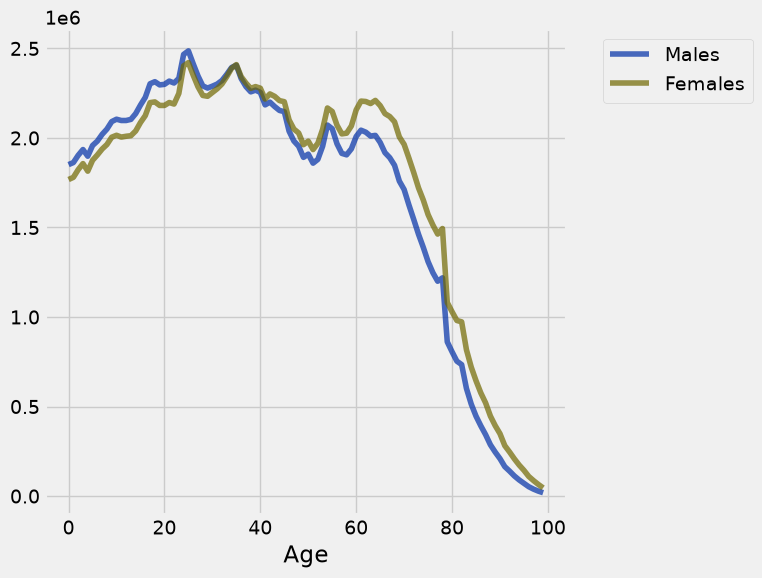

In [21]:
# datascience
pop_2025.plot('Age')


In [22]:
# polars
# hvplot
(lambda _df: _df.hvplot.line(x='Age', y=[c for c in _df.columns if c != 'Age']))(pop_2025_pl)


:NdOverlay   [Variable]
   :Curve   [Age]   (value)

**Discuss**: In a sentence, what data are represented by this line plot?

## Scatter Plots ##

Data from 2017: 50 top actors with the highest total gross domestic box office

In [23]:
# datascience
# Actors and their highest grossing movies
actors = Table.read_table('actors.csv')
actors


Actor,Total Gross,Number of Movies,Average per Movie,#1 Movie,Gross
Harrison Ford,4871.7,41,118.8,Star Wars: The Force Awakens,936.7
Samuel L. Jackson,4772.8,69,69.2,The Avengers,623.4
Morgan Freeman,4468.3,61,73.3,The Dark Knight,534.9
Tom Hanks,4340.8,44,98.7,Toy Story 3,415
"Robert Downey, Jr.",3947.3,53,74.5,The Avengers,623.4
Eddie Murphy,3810.4,38,100.3,Shrek 2,441.2
Tom Cruise,3587.2,36,99.6,War of the Worlds,234.3
Johnny Depp,3368.6,45,74.9,Dead Man's Chest,423.3
Michael Caine,3351.5,58,57.8,The Dark Knight,534.9
Scarlett Johansson,3341.2,37,90.3,The Avengers,623.4


In [24]:
# polars
# Actors and their highest grossing movies
actors_pl = pl.read_csv('actors.csv', eol_char='\r').with_columns(pl.col('Total Gross').str.strip_chars().cast(pl.Float64), pl.col('Average per Movie').str.strip_chars().cast(pl.Float64), pl.col('Gross').str.strip_chars().cast(pl.Float64))
actors_pl


Actor,Total Gross,Number of Movies,Average per Movie,#1 Movie,Gross
str,f64,i64,f64,str,f64
"""Harrison Ford""",4871.7,41,118.8,"""Star Wars: The Force Awakens""",936.7
"""Samuel L. Jackson""",4772.8,69,69.2,"""The Avengers""",623.4
"""Morgan Freeman""",4468.3,61,73.3,"""The Dark Knight""",534.9
"""Tom Hanks""",4340.8,44,98.7,"""Toy Story 3""",415.0
"""Robert Downey, Jr.""",3947.3,53,74.5,"""The Avengers""",623.4
…,…,…,…,…,…
"""Jeremy Renner""",2500.3,21,119.1,"""The Avengers""",623.4
"""Philip Seymour Hoffman""",2463.7,40,61.6,"""Catching Fire""",424.7
"""Sandra Bullock""",2462.6,35,70.4,"""Minions""",336.0


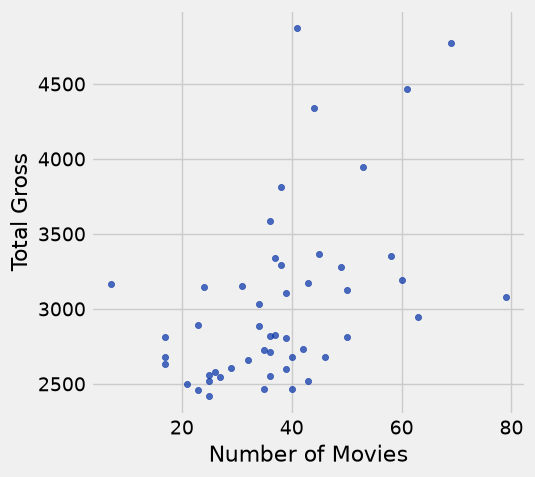

In [25]:
# datascience
actors.scatter('Number of Movies', 'Total Gross')


In [26]:
# polars
# hvplot
actors_pl.hvplot.scatter(x='Number of Movies', y='Total Gross')


:Scatter   [Number of Movies]   (Total Gross)

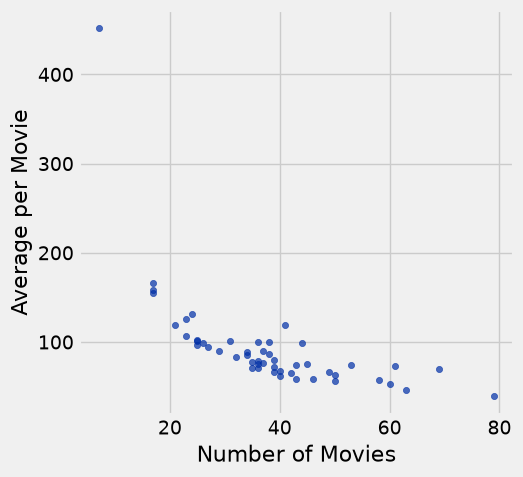

In [27]:
# datascience
actors.scatter('Number of Movies', 'Average per Movie')


In [28]:
# polars
# hvplot
actors_pl.hvplot.scatter(x='Number of Movies', y='Average per Movie')


:Scatter   [Number of Movies]   (Average per Movie)

Who is the outlier?

In [29]:
# datascience
actors.where('Average per Movie', are.above(400))


Actor,Total Gross,Number of Movies,Average per Movie,#1 Movie,Gross
Anthony Daniels,3162.9,7,451.8,Star Wars: The Force Awakens,936.7


In [30]:
# polars
actors_pl.filter((pl.col('Average per Movie') > (400)))


Actor,Total Gross,Number of Movies,Average per Movie,#1 Movie,Gross
str,f64,i64,f64,str,f64
"""Anthony Daniels""",3162.9,7,451.8,"""Star Wars: The Force Awakens""",936.7


## Bar Charts ##

In [31]:
# datascience
# Highest grossing movies as of 2017
top_movies = Table.read_table('top_movies_2017.csv')
top_movies


Title,Studio,Gross,Gross (Adjusted),Year
Gone with the Wind,MGM,198676459,1796176700,1939
Star Wars,Fox,460998007,1583483200,1977
The Sound of Music,Fox,158671368,1266072700,1965
E.T.: The Extra-Terrestrial,Universal,435110554,1261085000,1982
Titanic,Paramount,658672302,1204368000,1997
The Ten Commandments,Paramount,65500000,1164590000,1956
Jaws,Universal,260000000,1138620700,1975
Doctor Zhivago,MGM,111721910,1103564200,1965
The Exorcist,Warner Brothers,232906145,983226600,1973
Snow White and the Seven Dwarves,Disney,184925486,969010000,1937


In [32]:
# polars
# Highest grossing movies as of 2017
top_movies_pl = pl.read_csv('top_movies_2017.csv', eol_char='\r')
top_movies_pl


Title,Studio,Gross,Gross (Adjusted),Year
str,str,i64,i64,i64
"""Gone with the Wind""","""MGM""",198676459,1796176700,1939
"""Star Wars""","""Fox""",460998007,1583483200,1977
"""The Sound of Music""","""Fox""",158671368,1266072700,1965
"""E.T.: The Extra-Terrestrial""","""Universal""",435110554,1261085000,1982
"""Titanic""","""Paramount""",658672302,1204368000,1997
…,…,…,…,…
"""9 to 5""","""Fox""",103290500,341357800,1980
"""Batman v Superman: Dawn of Jus…","""Warner Brothers""",330360194,340137000,2016
"""The Firm""","""Paramount""",158348367,340028200,1993


In [33]:
# datascience
top10_adjusted = top_movies.take(np.arange(10))
top10_adjusted


Title,Studio,Gross,Gross (Adjusted),Year
Gone with the Wind,MGM,198676459,1796176700,1939
Star Wars,Fox,460998007,1583483200,1977
The Sound of Music,Fox,158671368,1266072700,1965
E.T.: The Extra-Terrestrial,Universal,435110554,1261085000,1982
Titanic,Paramount,658672302,1204368000,1997
The Ten Commandments,Paramount,65500000,1164590000,1956
Jaws,Universal,260000000,1138620700,1975
Doctor Zhivago,MGM,111721910,1103564200,1965
The Exorcist,Warner Brothers,232906145,983226600,1973
Snow White and the Seven Dwarves,Disney,184925486,969010000,1937


In [34]:
# polars
top10_adjusted_pl = top_movies_pl.gather(pl.int_range(10, eager=True))
top10_adjusted_pl


Title,Studio,Gross,Gross (Adjusted),Year
str,str,i64,i64,i64
"""Gone with the Wind""","""MGM""",198676459,1796176700,1939
"""Star Wars""","""Fox""",460998007,1583483200,1977
"""The Sound of Music""","""Fox""",158671368,1266072700,1965
"""E.T.: The Extra-Terrestrial""","""Universal""",435110554,1261085000,1982
"""Titanic""","""Paramount""",658672302,1204368000,1997
"""The Ten Commandments""","""Paramount""",65500000,1164590000,1956
"""Jaws""","""Universal""",260000000,1138620700,1975
"""Doctor Zhivago""","""MGM""",111721910,1103564200,1965
"""The Exorcist""","""Warner Brothers""",232906145,983226600,1973


In [35]:
# datascience
# Convert to millions of dollars for readability
millions = np.round(top10_adjusted.column('Gross (Adjusted)') / 1000000, 3)
top10_adjusted = top10_adjusted.with_column('Millions', millions)
top10_adjusted


Title,Studio,Gross,Gross (Adjusted),Year,Millions
Gone with the Wind,MGM,198676459,1796176700,1939,1796.18
Star Wars,Fox,460998007,1583483200,1977,1583.48
The Sound of Music,Fox,158671368,1266072700,1965,1266.07
E.T.: The Extra-Terrestrial,Universal,435110554,1261085000,1982,1261.09
Titanic,Paramount,658672302,1204368000,1997,1204.37
The Ten Commandments,Paramount,65500000,1164590000,1956,1164.59
Jaws,Universal,260000000,1138620700,1975,1138.62
Doctor Zhivago,MGM,111721910,1103564200,1965,1103.56
The Exorcist,Warner Brothers,232906145,983226600,1973,983.227
Snow White and the Seven Dwarves,Disney,184925486,969010000,1937,969.01


In [36]:
# polars
# Convert to millions of dollars for readability
millions_pl = (top10_adjusted_pl.get_column('Gross (Adjusted)') / 1000000).round(3)
top10_adjusted_pl = top10_adjusted_pl.with_columns(pl.Series('Millions', millions_pl))
top10_adjusted_pl


Title,Studio,Gross,Gross (Adjusted),Year,Millions
str,str,i64,i64,i64,f64
"""Gone with the Wind""","""MGM""",198676459,1796176700,1939,1796.177
"""Star Wars""","""Fox""",460998007,1583483200,1977,1583.483
"""The Sound of Music""","""Fox""",158671368,1266072700,1965,1266.073
"""E.T.: The Extra-Terrestrial""","""Universal""",435110554,1261085000,1982,1261.085
"""Titanic""","""Paramount""",658672302,1204368000,1997,1204.368
"""The Ten Commandments""","""Paramount""",65500000,1164590000,1956,1164.59
"""Jaws""","""Universal""",260000000,1138620700,1975,1138.621
"""Doctor Zhivago""","""MGM""",111721910,1103564200,1965,1103.564
"""The Exorcist""","""Warner Brothers""",232906145,983226600,1973,983.227


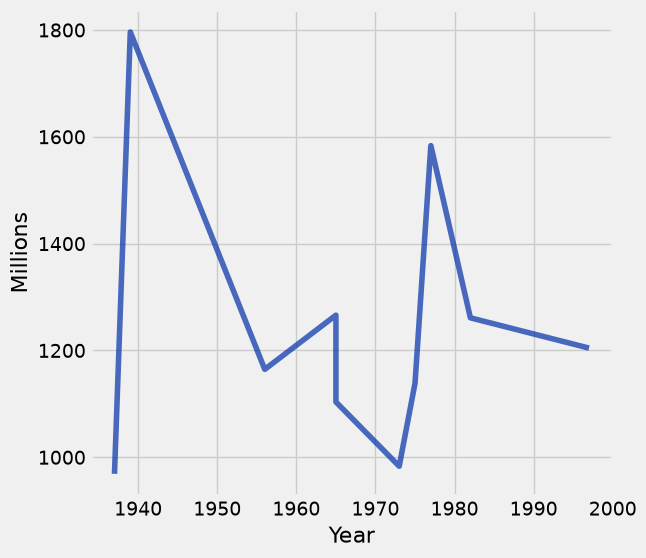

In [37]:
# datascience
# A line plot doesn't make sense here: don't do this!
top10_adjusted.plot('Year', 'Millions')


In [38]:
# polars
# hvplot
# A line plot doesn't make sense here: don't do this!
top10_adjusted_pl.hvplot.line(x='Year', y='Millions')


:Curve   [Year]   (Millions)

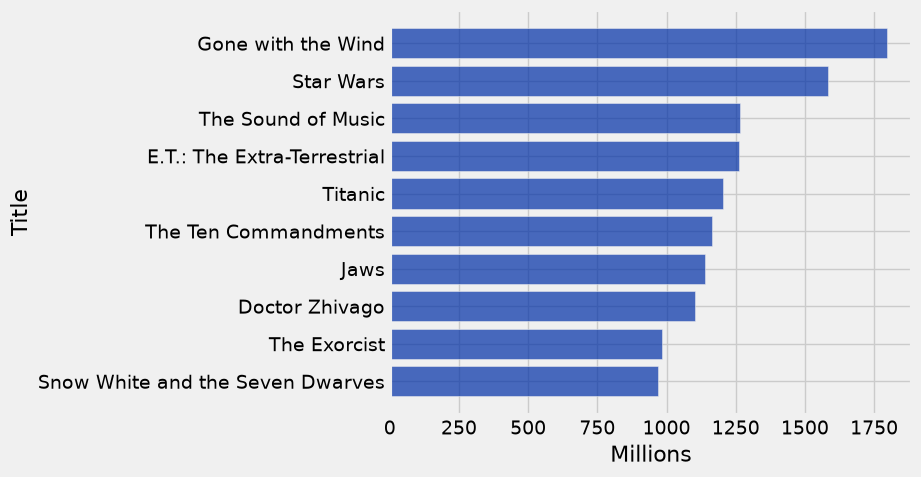

In [39]:
# datascience
top10_adjusted.barh('Title', 'Millions')


<BarContainer object of 10 artists>

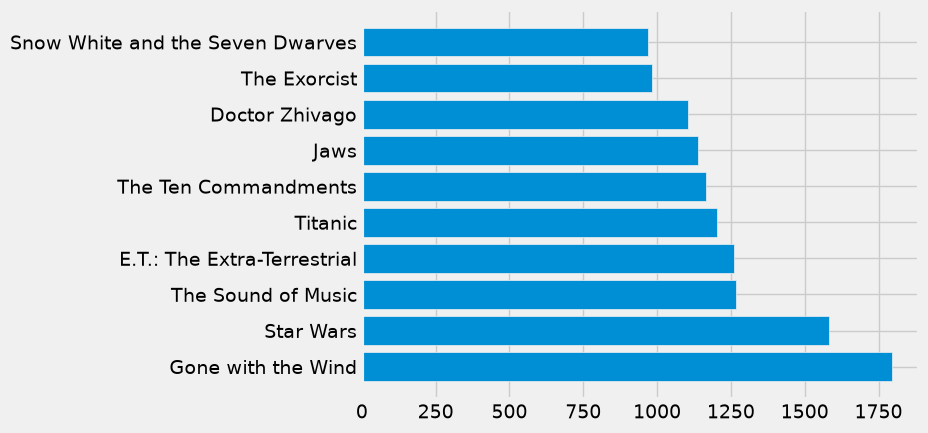

In [40]:
# polars
# matplotlib
plots.barh(top10_adjusted_pl.get_column('Title'), top10_adjusted_pl.get_column('Millions'))


**Exercise**: Generate the chart shown in the slides: a bar chart of age (# years since release) for the 10 highest grossing movies (non-adjusted).

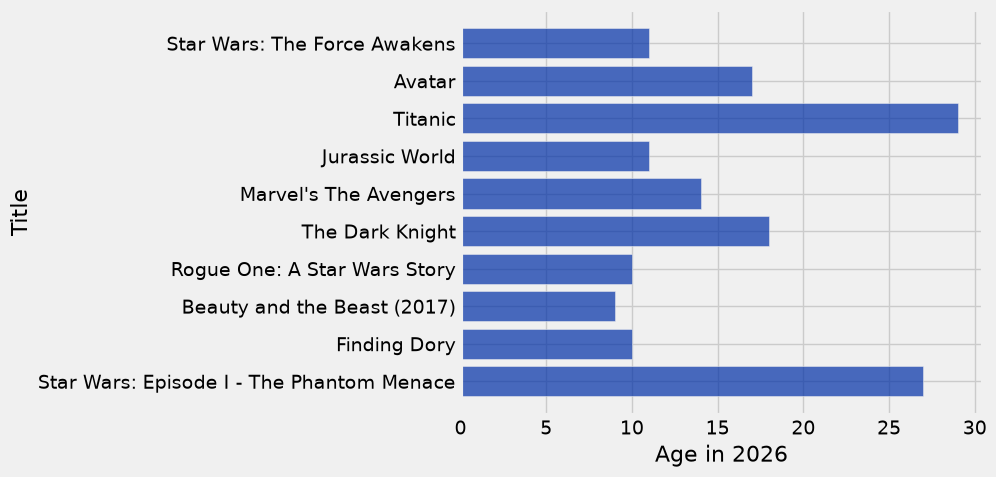

In [41]:
# datascience
# Get a table of the top 10 grossing movies (not adjusted for increasing ticket prices)
#  - sort then take *
# Compute the age of each of these movies
#  - get an array of the years they were released and subtract from 2026 *
# Put it all together in a bar chart
#  - use with_column to put ages into the table and then use barh

top10 = top_movies.sort('Gross', descending=True).take(np.arange(10))
ages = 2026 - top10.column('Year')
top10_with_age = top10.with_column('Age in 2026', ages)
top10_with_age.barh('Title', 'Age in 2026')


<BarContainer object of 10 artists>

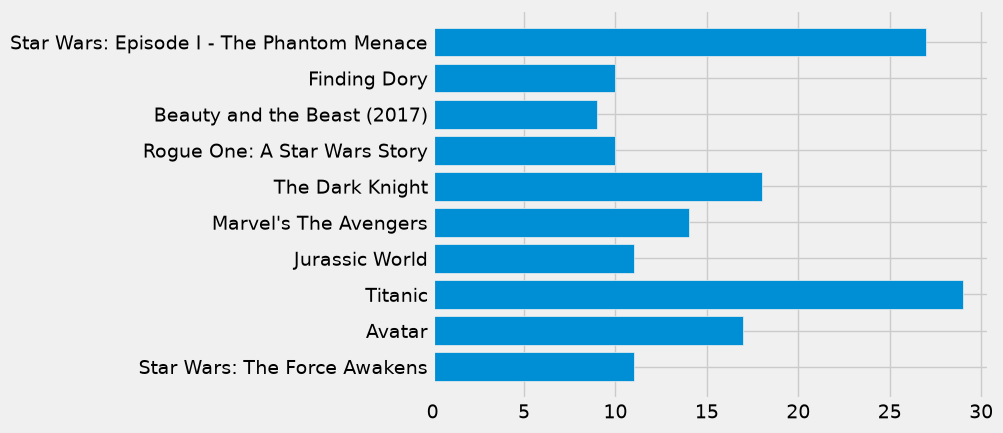

In [42]:
# polars
# matplotlib
# Get a table of the top 10 grossing movies (not adjusted for increasing ticket prices)
#  - sort then take *
# Compute the age of each of these movies
#  - get an array of the years they were released and subtract from 2026 *
# Put it all together in a bar chart
#  - use with_column to put ages into the table and then use barh

top10_pl = top_movies_pl.sort('Gross', descending=True).gather(pl.int_range(10, eager=True))
ages_pl = 2026 - top10_pl.get_column('Year')
top10_with_age_pl = top10_pl.with_columns(pl.Series('Age in 2026', ages_pl))
plots.barh(top10_with_age_pl.get_column('Title'), top10_with_age_pl.get_column('Age in 2026'))
